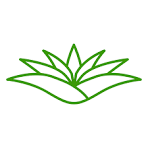

# are environmental conditions associated with residential listing prices?

## what problem does this project investigate?

This project examines whether air quality and green space are associated with residential listing prices. It combines data quality checks, a transparent relative environmental score, descriptive summaries, inferential tests, and a model that accounts for important property characteristics. The results describe patterns in the available listings; they do not establish that environmental conditions cause a change in price.

## 1. how can the property and environmental dataset be loaded reproducibly?

Load the enriched listing data from the project folders. The notebook checks common project-relative locations first and uses a clearly identified manual path only when needed. This keeps the workflow portable and makes the input file explicit.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

candidate_paths = [
    Path("../after/after_env.csv"),
    Path("data_analysis/after/after_env.csv"),
    Path("RealEstateDashBoard/data_analysis/after/after_env.csv"),
    Path("after_env.csv"),
]
DATA_PATH = next((path.resolve() for path in candidate_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "could not find after_env.csv. set DATA_PATH to the location of the project dataset."
    )

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"dataset path: {DATA_PATH}")
print(f"rows: {len(df):,}")
print(f"columns: {df.shape[1]:,}")
display(df.head())

dataset path: /mnt/data/nbtest/RealEstateDashBoard/data_analysis/after/after_env.csv
rows: 33,401
columns: 14


,type,size_sqm,bedrooms,bathrooms,floor,Furnished,region,city,price,view,price_per_sqm,class,air_quality,green_space
0,Apartment,170.000,3.000,2.000,9.000,No,Zahraa Al Maadi,Cairo,"1,546,400.000",Open View,"9,096.000",C,82.776,3.300
1,Apartment,104.000,2.000,1.000,7.000,No,Nasr City,Cairo,"950,000.000",Water View,"9,135.000",C,73.385,6.650
2,Apartment,160.000,3.000,2.000,1.000,No,Mostakbal City,Cairo,"2,100,000.000",Street View,"13,125.000",C,68.409,27.840
3,Apartment,160.000,3.000,3.000,0.000,No,New Cairo - El Tagamoa,Cairo,"3,994,232.000",Pool View,"24,964.000",B,70.299,3.550
4,Apartment,103.000,2.000,1.000,3.000,No,New Capital City,Cairo,"3,000,000.000",Garden / Green View,"29,126.000",B,65.451,31.110


## 2. what does the dataset contain, and which quality risks need attention?

Review the available fields, data types, missing values, duplicate rows, and numeric ranges before modifying the working data. The original input is retained in `df_raw` so later cleaning decisions can be checked against the source.

In [2]:
print("dataset structure")
display(pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
}).sort_values("missing_percent", ascending=False))

print(f"exact duplicate rows: {df.duplicated().sum():,}")

dataset structure


,data_type,non_missing,missing,missing_percent
floor,float64,13944,19457,58.250
air_quality,float64,31636,1765,5.280
green_space,float64,31636,1765,5.280
bedrooms,float64,33401,0,0.000
size_sqm,float64,33401,0,0.000
type,object,33401,0,0.000
Furnished,object,33401,0,0.000
bathrooms,float64,33401,0,0.000
region,object,33401,0,0.000
city,object,33401,0,0.000


exact duplicate rows: 1,095


In [3]:
expected_columns = [
    "type", "size_sqm", "bedrooms", "bathrooms", "floor", "Furnished",
    "region", "city", "price", "view", "price_per_sqm", "class",
    "air_quality", "green_space",
]
missing_columns = sorted(set(expected_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"required columns are missing: {missing_columns}")

numeric_columns = [
    "size_sqm", "bedrooms", "bathrooms", "floor", "price",
    "price_per_sqm", "air_quality", "green_space",
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

quality_checks = pd.Series({
    "nonpositive prices": int((df["price"].dropna() <= 0).sum()),
    "nonpositive areas": int((df["size_sqm"].dropna() <= 0).sum()),
    "negative air quality values": int((df["air_quality"].dropna() < 0).sum()),
    "negative green space values": int((df["green_space"].dropna() < 0).sum()),
    "duplicate rows": int(df.duplicated().sum()),
})
display(quality_checks.to_frame("count"))

,count
nonpositive prices,0
nonpositive areas,0
negative air quality values,0
negative green space values,0
duplicate rows,1095


## 3. are exact duplicate listings inflating the evidence?

Repeated rows can give the same listing extra weight in summaries and statistical tests. Remove only rows that match across every available column, preserve the original input in `df_raw`, and report the number removed. Similar listings with different values remain in the dataset.

In [4]:
exact_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(f"exact duplicate rows removed: {exact_duplicates:,}")
print(f"rows after exact deduplication: {len(df):,}")

exact duplicate rows removed: 1,095
rows after exact deduplication: 32,306


## 4. how should missing environmental measurements be handled consistently?

Fill missing values using the median for the same region first, then the same city, and finally the overall median when a group has no usable observations. Median imputation is less sensitive to extreme values, but it can reduce observed variation, so the number of imputed values must be considered when interpreting results.

In [5]:
environment_columns = ["air_quality", "green_space"]
missing_before = df[environment_columns].isna().sum()

for column in environment_columns:
    neighborhood_median = df.groupby("region", dropna=False)[column].transform("median")
    df[column] = df[column].fillna(neighborhood_median)

for column in environment_columns:
    city_median = df.groupby("city", dropna=False)[column].transform("median")
    df[column] = df[column].fillna(city_median)

for column in environment_columns:
    df[column] = df[column].fillna(df[column].median())

missing_after = df[environment_columns].isna().sum()
imputation_audit = pd.DataFrame({
    "missing_before": missing_before,
    "missing_after": missing_after,
    "values_filled": missing_before - missing_after,
})
display(imputation_audit)

if df[environment_columns].isna().any().any():
    warnings.warn("some environmental values remain missing after imputation")

,missing_before,missing_after,values_filled
air_quality,1750,0,1750
green_space,1750,0,1750


## 5. how can air quality and green space be combined into a transparent score?

Combine air quality and green space using the project weights. Since a lower air quality index indicates better air quality, reverse its percentile rank; retain the positive direction for green space, where higher values are better. The resulting score is relative to this dataset rather than an absolute environmental standard, and the chosen weights remain explicit assumptions.

In [6]:
df["aq_percentile"] = df["air_quality"].rank(method="average", pct=True)
df["aq_score"] = (1 - df["aq_percentile"]) * 100

df["green_percentile"] = df["green_space"].rank(method="average", pct=True)
df["green_score"] = df["green_percentile"] * 100

df["environment_score"] = (
    0.60 * df["aq_score"] + 0.40 * df["green_score"]
).round(2)

df["environment_class"] = pd.qcut(
    df["environment_score"],
    q=4,
    labels=["D", "C", "B", "A"],
    duplicates="drop",
)

print("score range")
print(df["environment_score"].min(), "to", df["environment_score"].max())
print("class distribution")
display(df["environment_class"].value_counts(dropna=False).sort_index().to_frame("listings"))

score range
0.52 to 81.87
class distribution


,listings
environment_class,
D,14782
C,3503
B,5989
A,8032


## 6. does the environmental score behave as intended, and how are listings distributed across classes?

Inspect the score distribution and the number of listings in each class. Class A represents higher relative environmental scores, while class D represents lower relative scores. This check helps reveal whether the score and class labels match the intended interpretation.

In [7]:
class_summary = df.groupby("environment_class", observed=True).agg(
    listings=("environment_score", "size"),
    score_mean=("environment_score", "mean"),
    score_median=("environment_score", "median"),
    air_quality_mean=("air_quality", "mean"),
    green_space_mean=("green_space", "mean"),
    price_median=("price", "median"),
    price_per_sqm_median=("price_per_sqm", "median"),
).round(2)
display(class_summary)

,listings,score_mean,score_median,air_quality_mean,green_space_mean,price_median,price_per_sqm_median
environment_class,,,,,,,
D,14782,37.170,41.050,71.040,3.240,"4,164,110.000","26,316.000"
C,3503,43.310,43.600,73.660,36.570,"4,670,000.000","26,316.000"
B,5989,56.460,57.030,58.480,5.310,"7,100,000.000","51,429.000"
A,8032,71.710,71.500,62.430,10.710,"4,850,000.000","30,769.000"


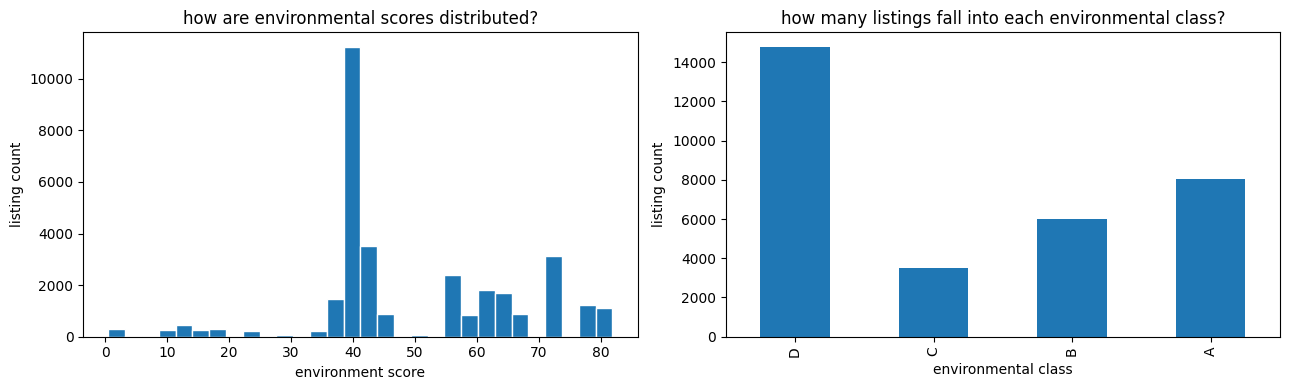

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["environment_score"].plot(kind="hist", bins=30, ax=axes[0], edgecolor="white")
axes[0].set_title("how are environmental scores distributed?")
axes[0].set_xlabel("environment score")
axes[0].set_ylabel("listing count")

class_order = [label for label in ["D", "C", "B", "A"] if label in df["environment_class"].astype(str).unique()]
df["environment_class"].value_counts().reindex(class_order).plot(kind="bar", ax=axes[1])
axes[1].set_title("how many listings fall into each environmental class?")
axes[1].set_xlabel("environmental class")
axes[1].set_ylabel("listing count")
plt.tight_layout()
plt.show()

# descriptive analysis

## what do the data show before any hypothesis tests are considered?

This stage describes the available listings, price distributions, environmental indicators, and regional differences. These summaries establish the context for the later inferential tests; they describe the sample and do not, by themselves, demonstrate statistically significant relationships.

## 7. how do property prices and environmental indicators vary across the dataset?

Listing prices may be right-skewed, so report medians alongside means. Use price per square meter as a complementary measure because total price is strongly affected by property size. Regional summaries provide context about local market differences before statistical tests are interpreted.

In [9]:
price_summary = df[["price", "price_per_sqm", "size_sqm", "air_quality", "green_space", "environment_score"]].describe().T
price_summary["median"] = df[["price", "price_per_sqm", "size_sqm", "air_quality", "green_space", "environment_score"]].median()
display(price_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,median
price,"32,306.000","10,373,337.050","18,865,689.160","400,000.000","2,200,000.000","4,700,000.000","12,300,000.000","840,000,000.000","4,700,000.000"
price_per_sqm,"32,306.000","49,240.820","120,159.580",1.000,"13,235.000","30,259.500","70,510.250","19,500,000.000","30,259.500"
size_sqm,"32,306.000",195.270,115.130,27.000,133.000,170.000,224.000,"1,560.000",170.000
air_quality,"32,306.000",66.860,7.880,49.040,65.450,70.300,70.300,86.090,70.300
green_space,"32,306.000",9.100,12.870,1.140,2.680,3.550,6.220,44.090,3.550
environment_score,"32,306.000",50.000,16.090,0.520,41.050,43.600,60.800,81.870,43.600


In [10]:
region_summary = df.groupby(["city", "region"], dropna=False).agg(
    listings=("price", "size"),
    median_price=("price", "median"),
    median_price_per_sqm=("price_per_sqm", "median"),
    median_environment_score=("environment_score", "median"),
    median_air_quality=("air_quality", "median"),
    median_green_space=("green_space", "median"),
).sort_values("listings", ascending=False)
display(region_summary.head(20).round(2))

listings   median_price  \
city        region                                                  
Cairo       New Cairo - El Tagamoa            5663  2,200,000.000   
            New Cairo City                    5018 11,700,000.000   
Giza        6 October City                    1964  8,572,500.000   
North Coast Ras Al Hekma                      1711 12,500,000.000   
Giza        Sheikh Zayed City                 1687  8,725,905.000   
            Sheikh Zayed                      1441  2,440,000.000   
Cairo       Madinaty                          1388  2,800,000.000   
Red Sea     Hurghada                          1386 11,000,000.000   
Cairo       New Capital City                  1099  2,559,000.000   
North Coast Sidi Abdel Rahman                 1003 18,500,000.000   
Giza        6th of October                     899  2,300,000.000   
North Coast Qesm Marsa Matrouh                 855 20,305,599.000   
Cairo       Shorouk City                       764  2,400,000.000   
            Mostakbal City - Future City       652  6,500,000.000   
North Coast Qesm Ad Dabaah                     636 18,000,000.000   
            Al Alamein                         552  7,215,000.000   
Suez        Al Ain Al Sokhna                   535  6,300,000.000   
Cairo       Nasr City                          484  1,620,700.000   
            Rehab City                         454  2,550,000.000   
            Obour City                         238  1,290,000.000   

                                          median_price_per_sqm  \
city        region                                               
Cairo       New Cairo - El Tagamoa                  11,871.000   
            New Cairo City                          62,963.000   
Giza        6 October City                          44,593.500   
North Coast Ras Al Hekma                            95,238.000   
Giza        Sheikh Zayed City                       49,057.000   
            Sheikh Zayed                            14,231.000   
Cairo       Madinaty                                19,680.000   
Red Sea     Hurghada                                84,000.000   
Cairo       New Capital City                        15,000.000   
North Coast Sidi Abdel Rahman                      109,143.000   
Giza        6th of October                          11,656.000   
North Coast Qesm Marsa Matrouh                     107,143.000   
Cairo       Shorouk City                            12,985.500   
            Mostakbal City - Future City            38,495.000   
North Coast Qesm Ad Dabaah                         106,633.500   
            Al Alamein                              55,283.000   
Suez        Al Ain Al Sokhna                        55,118.000   
Cairo       Nasr City                                9,091.000   
            Rehab City                              19,305.500   
            Obour City                               7,021.000   

                                          median_environment_score  \
city        region                                                   
Cairo       New Cairo - El Tagamoa                          41.050   
            New Cairo City                                  41.050   
Giza        6 October City                                  43.600   
North Coast Ras Al Hekma                                    64.060   
Giza        Sheikh Zayed City                               71.500   
            Sheikh Zayed                                    71.500   
Cairo       Madinaty                                        57.030   
Red Sea     Hurghada                                        38.230   
Cairo       New Capital City                                81.870   
North Coast Sidi Abdel Rahman                               60.800   
Giza        6th of October                                  43.600   
North Coast Qesm Marsa Matrouh                              58.330   
Cairo       Shorouk City                                    45.360   
            Mostakba

# inferential statistics

## do the observed patterns provide statistical evidence of relationships?

The next analyses test relationships and group differences using correlation tests, nonparametric comparisons, a chi-square test, and an adjusted regression model. Results should be interpreted using p-values, effect sizes, uncertainty, sample size, and test assumptions together. Statistical significance is not proof of causation or practical importance.

## 8. how strongly are environmental indicators associated with listing prices?

Pearson correlation measures linear association and can be sensitive to extreme values. Spearman correlation evaluates monotonic association using ranks. The correlation matrices and pairwise tests help identify relationships worth investigating, but correlation alone does not establish causation.

In [11]:
correlation_columns = [
    "price", "price_per_sqm", "size_sqm", "bedrooms", "bathrooms",
    "air_quality", "green_space", "environment_score",
]
correlation_data = df[correlation_columns].dropna()
pearson_matrix = correlation_data.corr(method="pearson")
spearman_matrix = correlation_data.corr(method="spearman")
print("pearson correlation")
display(pearson_matrix.round(3))
print("spearman correlation")
display(spearman_matrix.round(3))

pearson correlation


,price,price_per_sqm,size_sqm,bedrooms,bathrooms,air_quality,green_space,environment_score
price,1.000,0.288,0.564,0.491,0.511,-0.223,-0.068,0.042
price_per_sqm,0.288,1.000,0.062,0.105,0.114,-0.189,-0.064,0.042
size_sqm,0.564,0.062,1.000,0.690,0.698,0.024,0.051,-0.014
bedrooms,0.491,0.105,0.690,1.000,0.790,-0.068,0.060,0.040
bathrooms,0.511,0.114,0.698,0.790,1.000,-0.072,0.077,0.040
air_quality,-0.223,-0.189,0.024,-0.068,-0.072,1.000,0.296,-0.597
green_space,-0.068,-0.064,0.051,0.060,0.077,0.296,1.000,0.123
environment_score,0.042,0.042,-0.014,0.040,0.040,-0.597,0.123,1.000


spearman correlation


,price,price_per_sqm,size_sqm,bedrooms,bathrooms,air_quality,green_space,environment_score
price,1.000,0.923,0.317,0.419,0.477,-0.250,-0.214,0.080
price_per_sqm,0.923,1.000,-0.013,0.167,0.222,-0.335,-0.314,0.081
size_sqm,0.317,-0.013,1.000,0.725,0.745,0.152,0.171,-0.006
bedrooms,0.419,0.167,0.725,1.000,0.735,0.001,0.057,0.065
bathrooms,0.477,0.222,0.745,0.735,1.000,0.022,0.090,0.053
air_quality,-0.250,-0.335,0.152,0.001,0.022,1.000,0.406,-0.672
green_space,-0.214,-0.314,0.171,0.057,0.090,0.406,1.000,0.337
environment_score,0.080,0.081,-0.006,0.065,0.053,-0.672,0.337,1.000


In [12]:
relationship_rows = []
for x_column in ["air_quality", "green_space", "environment_score", "size_sqm"]:
    pair = df[[x_column, "price", "price_per_sqm"]].replace([np.inf, -np.inf], np.nan).dropna()
    if len(pair) >= 3:
        price_r, price_p = stats.spearmanr(pair[x_column], pair["price"])
        sqm_r, sqm_p = stats.spearmanr(pair[x_column], pair["price_per_sqm"])
        relationship_rows.append({
            "feature": x_column,
            "listings": len(pair),
            "spearman_with_price": price_r,
            "price_p_value": price_p,
            "spearman_with_price_per_sqm": sqm_r,
            "price_per_sqm_p_value": sqm_p,
        })
relationship_summary = pd.DataFrame(relationship_rows)
display(relationship_summary.round(5))

,feature,listings,spearman_with_price,price_p_value,spearman_with_price_per_sqm,price_per_sqm_p_value
0,air_quality,32306,-0.250,0.000,-0.335,0.000
1,green_space,32306,-0.214,0.000,-0.314,0.000
2,environment_score,32306,0.080,0.000,0.081,0.000
3,size_sqm,32306,0.317,0.000,-0.013,0.016


## 9. do listing prices differ across environmental classes, and how large are those differences?

Use the Kruskal-Wallis test to assess whether price distributions differ across environmental classes. This rank-based test is less dependent on normally distributed prices than one-way analysis of variance. Interpret p-values alongside group medians and an effect-size estimate, because statistical significance does not necessarily imply a practically important difference.

In [13]:
class_price_groups = [
    group["price"].dropna().to_numpy()
    for _, group in df.groupby("environment_class", observed=True)
    if group["price"].notna().sum() > 0
]
class_sqm_groups = [
    group["price_per_sqm"].dropna().to_numpy()
    for _, group in df.groupby("environment_class", observed=True)
    if group["price_per_sqm"].notna().sum() > 0
]

if len(class_price_groups) >= 2:
    price_h, price_p = stats.kruskal(*class_price_groups)
    n_price = sum(len(group) for group in class_price_groups)
    k_price = len(class_price_groups)
    epsilon_squared = max(0, (price_h - k_price + 1) / (n_price - k_price)) if n_price > k_price else np.nan
    print(f"price kruskal wallis statistic: {price_h:.3f}")
    print(f"price p value: {price_p:.6g}")
    print(f"price epsilon squared: {epsilon_squared:.4f}")

if len(class_sqm_groups) >= 2:
    sqm_h, sqm_p = stats.kruskal(*class_sqm_groups)
    n_sqm = sum(len(group) for group in class_sqm_groups)
    k_sqm = len(class_sqm_groups)
    sqm_epsilon_squared = max(0, (sqm_h - k_sqm + 1) / (n_sqm - k_sqm)) if n_sqm > k_sqm else np.nan
    print(f"price per square meter kruskal wallis statistic: {sqm_h:.3f}")
    print(f"price per square meter p value: {sqm_p:.6g}")
    print(f"price per square meter epsilon squared: {sqm_epsilon_squared:.4f}")

class_price_summary = df.groupby("environment_class", observed=True).agg(
    listings=("price", "count"),
    median_price=("price", "median"),
    mean_price=("price", "mean"),
    median_price_per_sqm=("price_per_sqm", "median"),
).round(2)
display(class_price_summary)

price kruskal wallis statistic: 541.289
price p value: 5.37133e-117
price epsilon squared: 0.0167
price per square meter kruskal wallis statistic: 1018.140
price per square meter p value: 2.08969e-220
price per square meter epsilon squared: 0.0314


,listings,median_price,mean_price,median_price_per_sqm
environment_class,,,,
D,14782,"4,164,110.000","9,566,355.310","26,316.000"
C,3503,"4,670,000.000","9,560,708.940","26,316.000"
B,5989,"7,100,000.000","14,987,218.520","51,429.000"
A,8032,"4,850,000.000","8,772,603.000","30,769.000"


## 10. are environmental classes associated with region, and where are listings concentrated?

Environmental conditions and property markets can vary by location. The chi-square test examines whether region and environmental class are associated, while the regional summaries show where observations are concentrated. Expected cell counts are checked because very small categories can make the test unreliable.

In [14]:
region_class_table = pd.crosstab(df["region"], df["environment_class"])
if region_class_table.shape[0] > 1 and region_class_table.shape[1] > 1:
    chi2, chi_p, chi_dof, expected = stats.chi2_contingency(region_class_table)
    print(f"chi square statistic: {chi2:.3f}")
    print(f"degrees of freedom: {chi_dof}")
    print(f"p value: {chi_p:.6g}")
    print(f"expected cells below five: {(expected < 5).sum():,} of {expected.size:,}")
    print("interpret the p value cautiously if many expected counts are small")
display(region_class_table.head(15))

chi square statistic: 96918.000
degrees of freedom: 360
p value: 0
expected cells below five: 221 of 484
interpret the p value cautiously if many expected counts are small


environment_class,D,C,B,A
region,,,,
15 May City,6,0,0,0
6 October City,0,1964,0,0
6th of October,0,899,0,0
Abasiya,8,0,0,0
Abu Qir,0,0,0,1
Abu Talat,0,0,0,8
Agouza,8,0,0,0
Al Agouza,8,0,0,0
Al Ain Al Sokhna,535,0,0,0


## 11. is the environmental score associated with price after accounting for key property characteristics?

A raw association may reflect differences in property size, type, furnishing, or location. This model uses log price and controls for size, bedrooms, bathrooms, furnishing status, property type, and city where available. The environmental-score coefficient estimates an adjusted association, not a causal effect. The model reports a clear message if required software or sufficient data are unavailable.

In [15]:
try:
    import statsmodels.formula.api as smf

    model_columns = [
        "price", "environment_score", "size_sqm", "bedrooms", "bathrooms",
        "Furnished", "type", "city",
    ]
    model_data = df[model_columns].replace([np.inf, -np.inf], np.nan).dropna().copy()
    model_data = model_data.loc[model_data["price"] > 0]
    model_data["log_price"] = np.log(model_data["price"])

    if len(model_data) >= 100 and model_data["city"].nunique() > 1:
        price_model = smf.ols(
            "log_price ~ environment_score + size_sqm + bedrooms + bathrooms + C(Furnished) + C(type) + C(city)",
            data=model_data,
        ).fit(cov_type="HC3")
        display(pd.DataFrame({
            "coefficient": price_model.params,
            "robust_standard_error": price_model.bse,
            "p_value": price_model.pvalues,
            "ci_lower": price_model.conf_int()[0],
            "ci_upper": price_model.conf_int()[1],
        }).round(5))
        print(f"observations used: {int(price_model.nobs):,}")
        print(f"adjusted r squared: {price_model.rsquared_adj:.4f}")
        score_coefficient = price_model.params.get("environment_score", np.nan)
        print(f"approximate price association per one score point: {(np.exp(score_coefficient) - 1) * 100:.3f} percent")
    else:
        print("not enough complete data or location variation to fit the adjusted model")
except ImportError:
    print("install statsmodels to run the adjusted price model")

,coefficient,robust_standard_error,p_value,ci_lower,ci_upper
Intercept,13.444,0.035,0.000,13.376,13.512
C(Furnished)[T.Yes],0.287,0.014,0.000,0.260,0.314
C(type)[T.Chalet],0.296,0.019,0.000,0.260,0.333
C(type)[T.Duplex],-0.138,0.027,0.000,-0.190,-0.086
C(type)[T.Penthouse],0.226,0.030,0.000,0.167,0.285
C(type)[T.Roof],0.665,0.134,0.000,0.403,0.927
C(type)[T.Stand Alone Villa],-0.979,0.036,0.000,-1.048,-0.909
C(type)[T.Studio],-0.251,0.040,0.000,-0.329,-0.172
C(type)[T.Townhouse],0.254,0.026,0.000,0.203,0.305
C(type)[T.Twin House],0.404,0.034,0.000,0.336,0.471


observations used: 32,306
adjusted r squared: 0.5175
approximate price association per one score point: 0.330 percent


## 12. do neighborhood rankings remain stable when environmental-score weights change?

The main score assigns 60 percent weight to air quality and 40 percent to green space. The sensitivity check recalculates scores using alternative plausible weights and compares neighborhood rankings. Large changes would mean that conclusions depend on the chosen weighting scheme and should be reported transparently.

In [16]:
weight_scenarios = {
    "air quality focused": (0.80, 0.20),
    "project baseline": (0.60, 0.40),
    "equal weights": (0.50, 0.50),
    "green space focused": (0.30, 0.70),
}

sensitivity = df[["city", "region", "aq_score", "green_score"]].copy()
for scenario, (aq_weight, green_weight) in weight_scenarios.items():
    sensitivity[scenario] = aq_weight * sensitivity["aq_score"] + green_weight * sensitivity["green_score"]

neighborhood_scores = sensitivity.groupby(["city", "region"], dropna=False).agg(
    **{scenario: (scenario, "median") for scenario in weight_scenarios}
)
for scenario in weight_scenarios:
    neighborhood_scores[f"{scenario} rank"] = neighborhood_scores[scenario].rank(ascending=False, method="average")

rank_columns = [f"{scenario} rank" for scenario in weight_scenarios]
rank_stability = neighborhood_scores[rank_columns].corr(method="spearman").round(3)
print("rank correlation between weighting scenarios")
display(rank_stability)
print("neighborhoods with the largest rank range across scenarios")
neighborhood_scores["rank_range"] = neighborhood_scores[rank_columns].max(axis=1) - neighborhood_scores[rank_columns].min(axis=1)
display(neighborhood_scores.sort_values("rank_range", ascending=False).head(15).round(2))

rank correlation between weighting scenarios


,air quality focused rank,project baseline rank,equal weights rank,green space focused rank
air quality focused rank,1.000,0.979,0.965,0.827
project baseline rank,0.979,1.000,0.995,0.906
equal weights rank,0.965,0.995,1.000,0.927
green space focused rank,0.827,0.906,0.927,1.000


neighborhoods with the largest rank range across scenarios


air quality focused  \
city        region                                              
North Coast Ras Al Hekma                               80.710   
Cairo       Mostakbal City                             60.830   
            Mostakbal City - Future City               60.830   
Giza        Sheikh Zayed                               69.950   
            Sheikh Zayed City                          69.950   
Cairo       Badr City                                  44.130   
Red Sea     Hurghada                                   49.820   
            Marsa Alam                                 42.440   
Cairo       New Capital City                           79.490   
North Coast Hacienda                                   76.350   
            Fuka                                       76.350   
            Coronado                                   76.350   
            Markaz Al Hamam                            76.350   
            Coast Heights                              76.350   
            Qesm Marsa Matrouh                         73.060   

                                          project baseline  equal weights  \
city        region                                                          
North Coast Ras Al Hekma                            64.060         55.740   
Cairo       Mostakbal City                          66.770         69.740   
            Mostakbal City - Future City            66.770         69.740   
Giza        Sheikh Zayed                            71.500         72.270   
            Sheikh Zayed City                       71.500         72.270   
Cairo       Badr City                               33.370         27.990   
Red Sea     Hurghada                                38.230         32.430   
            Marsa Alam                              32.690         27.820   
Cairo       New Capital City                        81.870         83.060   
North Coast Hacienda                                60.800         53.020   
            Fuka                                    60.800         53.020   
            Coronado                                60.800         53.020   
            Markaz Al Hamam                         60.800         53.020   
            Coast Heights                           60.800         53.020   
            Qesm Marsa Matrouh                      58.330         50.960   

                                          green space focused  \
city        region                                              
North Coast Ras Al Hekma                               39.100   
Cairo       Mostakbal City                             75.670   
            Mostakbal City - Future City               75.670   
Giza        Sheikh Zayed                               73.820   
            Sheikh Zayed City                          73.820   
Cairo       Badr City                                  17.220   
Red Sea     Hurghada                                   20.840   
            Marsa Alam                                 18.070   
Cairo       New Capital City                           85.440   
North Coast Hacienda                                   37.470   
            Fuka                                       37.470   
            Coronado                                   37.470   
            Markaz Al Hamam                            37.470   
            Coast Heights                              37.470   
            Qesm Marsa Matrouh                         36.230   

                                          air quality focused rank  \
city        region                                                   
North Coast Ras Al Hekma                                    10.000   
Cairo       Mostakbal City                                  56.500   
            Mostakbal City - Future City                    56.500   
Giza        Sheikh Zayed                                    53.500   
            Sheikh Zayed City                               53.500   
Cairo       Badr City         

## 13. what patterns are visible when prices are compared with environmental classes and scores?

These charts bring the main comparisons together. Grouped price summaries use medians to reduce the influence of extreme listing prices, while the score-versus-price chart helps reveal the overall pattern and spread without implying causation.

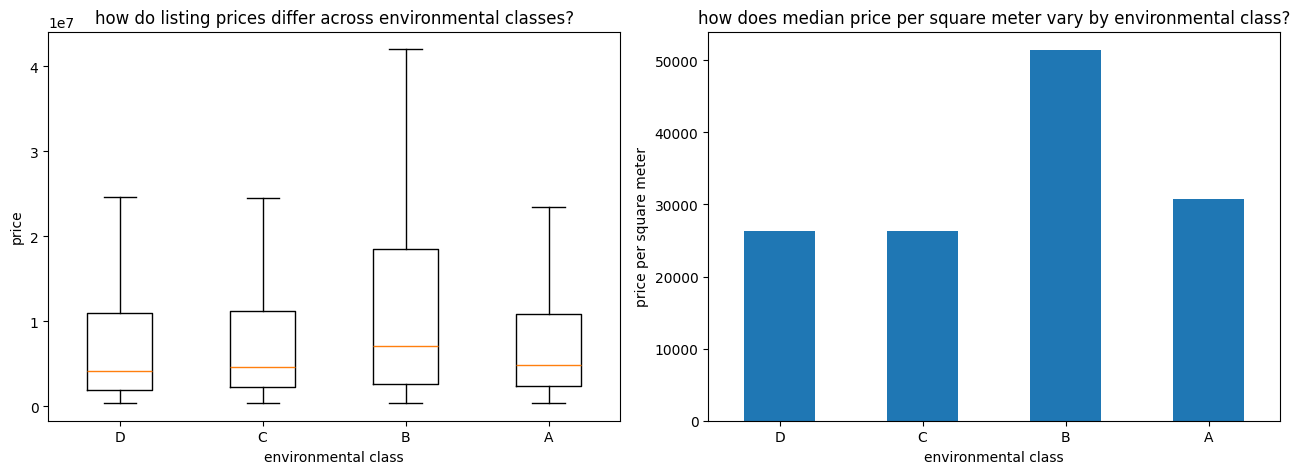

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
class_order = [label for label in ["D", "C", "B", "A"] if label in df["environment_class"].astype(str).unique()]
price_by_class = [df.loc[df["environment_class"] == label, "price"].dropna() for label in class_order]
axes[0].boxplot(price_by_class, tick_labels=class_order, showfliers=False)
axes[0].set_title("how do listing prices differ across environmental classes?")
axes[0].set_xlabel("environmental class")
axes[0].set_ylabel("price")

median_sqm = df.groupby("environment_class", observed=True)["price_per_sqm"].median().reindex(class_order)
median_sqm.plot(kind="bar", ax=axes[1])
axes[1].set_title("how does median price per square meter vary by environmental class?")
axes[1].set_xlabel("environmental class")
axes[1].set_ylabel("price per square meter")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

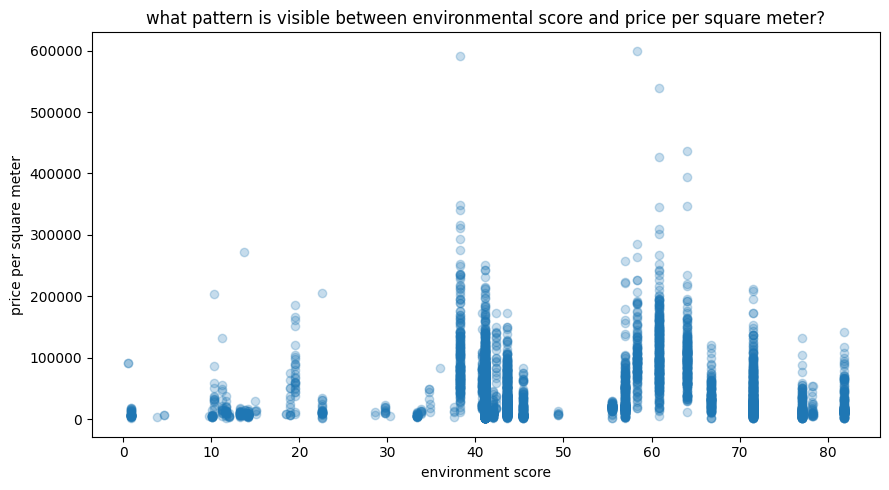

In [18]:
plot_data = df[["environment_score", "price_per_sqm"]].replace([np.inf, -np.inf], np.nan).dropna()
if len(plot_data) > 5000:
    plot_data = plot_data.sample(5000, random_state=42)

plt.figure(figsize=(9, 5))
plt.scatter(plot_data["environment_score"], plot_data["price_per_sqm"], alpha=0.25)
plt.xlabel("environment score")
plt.ylabel("price per square meter")
plt.title("what pattern is visible between environmental score and price per square meter?")
plt.tight_layout()
plt.show()

## 14. how can the cleaned and enriched dataset support reproducible follow-up work?

Save the analysis-ready data, including the derived environmental scores and classes, to a separate output file. The raw input is not overwritten, allowing the exported results to be traced back to the source and reused in further analysis.

In [19]:
OUTPUT_PATH = DATA_PATH.parent / "environment_analysis_output.csv"
df.to_csv(OUTPUT_PATH, index=False)
print(f"analysis dataset saved to: {OUTPUT_PATH}")
print(f"final rows: {len(df):,}")
print(f"remaining missing environmental values: {int(df[environment_columns].isna().sum().sum()):,}")

analysis dataset saved to: /mnt/data/nbtest/RealEstateDashBoard/data_analysis/after/environment_analysis_output.csv
final rows: 32,306
remaining missing environmental values: 0


## 15. what can the findings support, and which limitations must guide interpretation?

The environmental score is a relative ranking based on selected variables and assumed weights. Median imputation can hide local variation and does not replace direct environmental measurements. Listing data represent advertised prices rather than verified completed transactions. Location, property size, property type, and amenities may influence both environmental exposure and price. In large datasets, very small p-values can occur even when practical effects are limited. This observational analysis identifies associations, not causation. Final conclusions should also consider source definitions, collection dates, and geographic coverage.

## what is the most responsible conclusion and next step?

This notebook provides a reproducible first assessment of whether local air quality and green space are associated with advertised residential prices. The most defensible interpretation comes from considering adjusted estimates alongside effect sizes, uncertainty, data coverage, and the sensitivity of the environmental score. A stronger next study would align verified environmental measurements with completed sale prices over matching dates and locations, then test whether the observed relationships persist. Until those checks are available, the findings should guide further investigation rather than support causal, valuation, or investment claims.

**the result is a clearer evidence base for asking better questions about environmental quality and housing markets.**